# Lab 0.5: ทัวร์ machine learning แบบดั้งเดิม

**SC 677 805 Deep Learning for Data Analytics**
M.Sc. in Statistics and Data Science, Faculty of Science, Khon Kaen University

แลปสั้น ใช้เวลาประมาณชั่วโมงครึ่ง มี 8 ข้อ

ก่อนจะสร้างโครงข่ายประสาทเทียม ควรรู้จักสิ่งที่มันต้องเอาชนะเสียก่อน แลปนี้พาไปรู้จักสามวิธี
ที่เก่าแก่กว่า เรียบง่ายกว่า และ **ยังชนะ deep learning อยู่บ่อย ๆ กับข้อมูลตาราง**

| วิธี | คิดอย่างไร | ฝึกอย่างไร |
| --- | --- | --- |
| k-nearest neighbors | ของที่อยู่ใกล้กันมักเป็นพวกเดียวกัน | ไม่ต้องฝึก จำข้อมูลไว้เฉย ๆ |
| decision tree | ถามคำถามที่ลดความไม่แน่นอนได้มากที่สุดก่อน | แบ่งข้อมูลแบบละโมบ ทีละคำถาม |
| support vector machine | หาเส้นแบ่งที่มีระยะขอบกว้างที่สุด | แก้ปัญหาการหาค่าเหมาะที่สุดแบบมีเงื่อนไข |

สามวิธีนี้จะกลับมาอีกครั้งตอนปลายเทอม ในฐานะ **คู่เทียบ** ทุกครั้งที่เรารายงานผลของโครงข่าย
ประสาทเทียม เราจะต้องรายงานผลของวิธีเหล่านี้ไว้ข้าง ๆ เสมอ เป็นกติกาของวิชานี้

### รูปแบบของแลป

ต่างจาก Lab 0 และ Lab 1 ตรงที่แลปนี้จะ**อธิบายทฤษฎีให้จบก่อน แล้วค่อยให้เติมโค้ด**
ทุกข้อมีสูตร มีตัวอย่างที่คำนวณด้วยมือไว้แล้ว แล้วจึงเป็นช่องว่าง เขียนไม่เกินสามสี่บรรทัดต่อข้อ

### กติกาที่ต่างจากแลปอื่น

**แลปนี้อนุญาตให้ใช้ scikit-learn ได้** ในส่วนที่ระบุไว้ เหตุผลคือ SVM ต้องแก้ปัญหา
การหาค่าเหมาะที่สุดแบบมีเงื่อนไข ซึ่งไม่มีใครเขียนเองในชีวิตจริง และวิธีแก้นั้นก็ไม่ได้สอนอะไร
เกี่ยวกับ SVM เลย เราจึงเขียนเองเฉพาะส่วนที่เป็น**แนวคิด** คือ hinge loss, ระยะขอบ และ kernel
ส่วนการฝึกปล่อยให้ sklearn ทำ

ส่วน kNN กับ decision tree ยังต้องเขียนเอง เพราะสั้นและแนวคิดอยู่ในโค้ดทั้งหมด

### คะแนน

| ส่วน | หัวข้อ | ข้อ | คะแนน |
| --- | --- | --- | --- |
| 1 | k-nearest neighbors | 2 | 24 |
| 2 | decision tree | 3 | 42 |
| 3 | support vector machine | 3 | 34 |
| 4 | เปรียบเทียบทั้งสามวิธี | 0 | ไม่คิดคะแนน แต่ต้องส่ง |

ถ้าติดตรงไหน ให้กลับไปดู Lab 0 ก่อน ทุกข้อในแลปนี้สร้างจากดริลใน Lab 0 ทั้งสิ้น

## Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

np.set_printoptions(precision=4, suppress=True)
print("NumPy", np.__version__)

SCORES, MAXPTS = {}, {}


def grade(name, points, *tests):
    MAXPTS[name] = points
    problems = []
    for t in tests:
        try:
            t()
        except AssertionError as e:
            problems.append("FAIL  %s: %s" % (t.__name__, str(e) or "assertion failed"))
        except Exception as e:
            problems.append("ERROR %s: %s: %s" % (t.__name__, type(e).__name__, e))
    SCORES[name] = 0 if problems else points
    print("[%s] %-28s %3d / %d" % ("PASS" if not problems else "----",
                                   name, SCORES[name], points))
    for p in problems:
        print("         " + p)


def report():
    names = {"1": "k-nearest neighbors", "2": "decision tree",
             "3": "support vector machine"}
    parts = {}
    for k in MAXPTS:
        s = k.split(".")[0]
        got, mx = parts.get(s, (0, 0))
        parts[s] = (got + SCORES.get(k, 0), mx + MAXPTS[k])
    print("%-4s %-28s %s" % ("", "", "score"))
    print("-" * 46)
    for s in sorted(parts):
        g, m = parts[s]
        print("%-4s %-28s %4d / %-4d" % (s, names.get(s, ""), g, m))
    print("-" * 46)
    print("%-33s %4d / %-4d" % ("TOTAL", sum(SCORES.values()), sum(MAXPTS.values())))


print("grade() และ report() พร้อมใช้งาน")

### ข้อมูลที่ใช้ทั้งแลป

ใช้ชุดเดียวตลอด เพื่อให้เปรียบเทียบทั้งสามวิธีได้ตรง ๆ ในตอนท้าย

เป็นข้อมูลสองมิติ สองกลุ่ม รูปร่างเหมือนพระจันทร์เสี้ยวสองอันเกี่ยวกัน เลือกชุดนี้เพราะ
**เส้นตรงเส้นเดียวแบ่งไม่ได้** จึงเห็นความต่างของแต่ละวิธีชัดเจน และสองมิติทำให้วาดเส้นแบ่งเขตดูได้

สังเกตว่าข้อมูลที่นี่เก็บเป็น `(n, p)` คือหนึ่งแถวต่อหนึ่งตัวอย่าง เหมือน Lab 0 ส่วนที่ 1 และ 2

In [ ]:
try:
    from sklearn.datasets import make_moons

    X_all, y_all = make_moons(n_samples=400, noise=0.25, random_state=0)
    X_tr, y_tr = X_all[::2], y_all[::2]        # ครึ่งหนึ่งเป็นชุดฝึก
    X_te, y_te = X_all[1::2], y_all[1::2]      # อีกครึ่งเป็นชุดทดสอบ

    print("ชุดฝึก  ", X_tr.shape, y_tr.shape)
    print("ชุดทดสอบ", X_te.shape, y_te.shape)
    print("สัดส่วนกลุ่ม 1 ในชุดฝึก", y_tr.mean())

    plt.figure(figsize=(5.2, 4))
    plt.scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap="coolwarm", s=18, edgecolors="k", linewidths=.3)
    plt.xlabel("feature 0")
    plt.ylabel("feature 1")
    plt.title("training data")
    plt.show()
except Exception as _e:
    print("เซลล์นี้ต้องทำข้อข้างบนให้เสร็จก่อน")
    print("  %s: %s" % (type(_e).__name__, _e))


---
# 1. k-nearest neighbors (24 คะแนน)

### ทฤษฎี

kNN ตั้งอยู่บนสมมติฐานข้อเดียว คือ **ของที่อยู่ใกล้กันในปริภูมิคุณลักษณะ มักมีป้ายกำกับเดียวกัน**

ขั้นตอนทั้งหมดมีสามขั้น

1. วัดระยะจากจุดที่อยากทำนาย ไปยังจุดในชุดฝึกทุกจุด
2. หยิบ $K$ จุดที่ใกล้ที่สุด
3. ให้ $K$ จุดนั้นโหวตกัน ป้ายไหนได้เสียงมากสุดก็ตอบอันนั้น

$$d(\mathbf{a}, \mathbf{b}) = \sqrt{\sum_k (a_k - b_k)^2}$$

**ไม่มีขั้นตอนการฝึก** โมเดลคือชุดข้อมูลฝึกทั้งก้อน งานทั้งหมดเกิดตอนทำนาย
ซึ่งตรงข้ามกับทุกวิธีที่เหลือในวิชานี้ เรียกว่า lazy learning

**$K$ คือปุ่มความยืดหยุ่น** $K=1$ คือยืดหยุ่นที่สุด ทุกจุดในชุดฝึกสร้างอาณาเขตของตัวเองได้
ส่วน $K=n$ คือตอบป้ายที่พบบ่อยที่สุดเหมือนกันหมดทุกจุด องศาอิสระประสิทธิผลคือ $n/K$
ดังนั้น $K$ เล็กแปลว่ายืดหยุ่นมาก ซึ่งกลับทางกับสัญชาตญาณของคนส่วนใหญ่

### 1.1 `compute_distance` (12 คะแนน)

สร้างตารางระยะทางระหว่างทุกจุดทดสอบกับทุกจุดฝึก

$$D_{ij} = \lVert \mathbf{x}^{\text{test}}_i - \mathbf{x}^{\text{train}}_j \rVert_2$$

**ตัวอย่างที่คำนวณให้แล้ว**

```
Xtrain = [[0, 1],      Xtest = [[0, 1],
          [1, 0],               [1, 1]]
          [1, 1]]

แถวที่ 0 ของ D คือระยะจากจุดทดสอบ (0,1) ไปยังจุดฝึกทั้งสามตัว
    ไป (0,1)  ->  sqrt(0 + 0) = 0
    ไป (1,0)  ->  sqrt(1 + 1) = 1.4142
    ไป (1,1)  ->  sqrt(1 + 0) = 1

แถวที่ 1 ของ D คือระยะจากจุดทดสอบ (1,1)
    ไป (0,1)  ->  sqrt(1 + 0) = 1
    ไป (1,0)  ->  sqrt(0 + 1) = 1
    ไป (1,1)  ->  sqrt(0 + 0) = 0

D = [[0,      1.4142, 1],
     [1,      1,      0]]        ขนาด (2, 3)
```

**ระวังเรื่องรูปร่าง** แถวคือจุดทดสอบ คอลัมน์คือจุดฝึก ดังนั้นได้ `(n_test, n_train)`
ไม่ใช่จัตุรัส ถ้าสลับจะไม่ error แต่คำตอบผิดหมด

**คำใบ้** เขียนได้สามแบบ **คะแนนเต็มเหมือนกันทั้งสามแบบ** เลือกแบบที่คุณเข้าใจ

1. **ลูปสองชั้น** ช่องละหนึ่งครั้ง ข้างในคือ Lab 0 ข้อ 3.2 `euclidean` ตรง ๆ
   สร้างตารางเปล่าด้วย `np.zeros((n_test, n_train))` ก่อน แล้วเติมทีละช่อง
   แบบนี้ตรงกับสูตรที่สุด เริ่มจากอันนี้ได้เลย

2. **ลูปชั้นเดียว** แถวละหนึ่งครั้ง สังเกตว่าระยะจากจุดทดสอบตัวเดียวไปยังจุดฝึกทุกตัว
   คำนวณพร้อมกันได้ เพราะ `Xtrain` ขนาด `(n_train, p)` ลบกับ `Xtest[i]` ขนาด `(p,)`
   ได้เลยด้วย broadcasting คือลวดลายเดียวกับ Lab 0 ข้อ 2.4 `center`
   แล้วรวมตาม `axis=1` ตามกฎใน Lab 0 หัวข้อ 3

3. **ไม่มีลูปเลย** ยืดทั้งสองก้อนให้เป็นสามมิติแล้วให้ broadcasting จับคู่ให้ครบ
   `Xtest.reshape(n_test, 1, p)` กับ `Xtrain.reshape(1, n_train, p)`
   ลบกันได้ก้อนขนาด `(n_test, n_train, p)` แล้วยกกำลังสองและรวมตาม `axis=2`

**ถ้าติด** Lab 0 ข้อ 3.2 `euclidean` คือข้อนี้สำหรับจุดคู่เดียว

In [ ]:
def compute_distance(Xtrain, Xtest):
    '''
    ระยะทางแบบยุคลิดระหว่างทุกจุดทดสอบกับทุกจุดฝึก
    ใส่เข้า : Xtrain ขนาด (n_train, p), Xtest ขนาด (n_test, p)
    ได้ออก  : D ขนาด (n_test, n_train)
    '''
    #########################################
    ## เขียนโค้ดของคุณตรงนี้ / INSERT YOUR CODE HERE
    D = None
    #########################################
    return D

In [ ]:
def test_compute_distance():
    Xtrain = np.array([[0., 1.], [1., 0.], [1., 1.]])
    Xtest = np.array([[0., 1.], [1., 1.]])
    D = compute_distance(Xtrain, Xtest)
    assert D is not None, "ยังไม่ได้เขียนโค้ด ฟังก์ชันคืนค่า None"
    assert D.shape == (2, 3), "ต้องได้ (n_test, n_train) = (2, 3) แต่ได้ %s" % (D.shape,)
    assert np.allclose(D, [[0., 1.41421356, 1.], [1., 1., 0.]], atol=1e-6)


def test_compute_distance_properties():
    rng = np.random.default_rng(0)
    A = rng.normal(0., 1., (6, 3))
    D = compute_distance(A, A)
    assert np.allclose(np.diag(D), 0., atol=1e-12), "ระยะจากจุดหนึ่งไปหาตัวเองต้องเป็นศูนย์"
    assert np.allclose(D, D.T), "ตารางระยะทางของข้อมูลชุดเดียวกับตัวเองต้องสมมาตร"
    assert np.all(D >= 0), "ระยะทางติดลบไม่ได้ ลืมยกกำลังสองหรือเปล่า"


grade("1.1 compute_distance", 12, test_compute_distance, test_compute_distance_properties)

### 1.2 `knn_predict` (12 คะแนน)

ทำนายป้ายของทุกจุดทดสอบ ด้วยการโหวตจาก $K$ เพื่อนบ้านที่ใกล้ที่สุด

**ตัวอย่างที่คำนวณให้แล้ว** สมมติแถวแรกของ $D$ คือ

```
D[0] = [0.9, 0.2, 0.5, 0.1, 0.7]      ระยะไปยังจุดฝึกทั้งห้าจุด
Ytrain = [ a ,  b ,  b ,  b ,  a ]

เรียงลำดับตำแหน่งจากใกล้ไปไกล  ->  [3, 1, 2, 4, 0]
เอาสามตัวแรก (K=3)            ->  [3, 1, 2]
ป้ายของสามตัวนั้น              ->  ['b', 'b', 'b']
โหวต                          ->  'b'
```

**คำใบ้สามขั้น** ขั้นแรกเรียกฟังก์ชันข้อที่แล้ว อย่าเขียนระยะทางใหม่
ขั้นที่สองใช้ `np.argsort` แล้วตัดเอา $K$ ตัวแรก
ขั้นที่สามนับป้ายแล้วหยิบตัวที่มากที่สุด

**ถ้าติด** Lab 0 ข้อ 5.4 `k_nearest_index` ทำขั้นที่สองไว้แล้ว และข้อ 5.3 `most_frequent` ทำขั้นที่สาม

In [ ]:
def knn_predict(Xtrain, Ytrain, Xtest, K=3):
    '''
    ทำนายป้ายด้วยการโหวตจาก K เพื่อนบ้านที่ใกล้ที่สุด
    ใส่เข้า : Xtrain (n_train, p), Ytrain ความยาว n_train, Xtest (n_test, p), K จำนวนเพื่อนบ้าน
    ได้ออก  : Ypred เป็น ndarray ความยาว n_test
    '''
    #########################################
    ## เขียนโค้ดของคุณตรงนี้ / INSERT YOUR CODE HERE
    Ypred = None
    #########################################
    return Ypred

In [ ]:
def test_knn_predict_k1():
    Xtrain = np.array([[0., 1.], [1., 0.], [1., 1.]])
    Ytrain = np.array([1, 2, 3])
    Xtest = np.array([[0., 1.], [1., 1.]])
    out = knn_predict(Xtrain, Ytrain, Xtest, K=1)
    assert out is not None, "ยังไม่ได้เขียนโค้ด ฟังก์ชันคืนค่า None"
    assert len(out) == 2, "ต้องได้คำตอบหนึ่งค่าต่อหนึ่งจุดทดสอบ"
    assert list(out) == [1, 3], "K=1 แต่ละจุดต้องได้ป้ายของจุดฝึกที่ใกล้ที่สุด"


def test_knn_predict_vote():
    Xtrain = np.array([[0., 1.], [1., 0.], [1., 1.]])
    Xtest = np.array([[0., 1.], [1., 1.]])
    out = knn_predict(Xtrain, np.array([1, 2, 2]), Xtest, K=3)
    assert list(out) == [2, 2], "K=3 เห็นครบทุกจุด ป้ายที่พบบ่อยที่สุดต้องชนะ"


def test_knn_predict_on_the_dataset():
    acc = (knn_predict(X_tr, y_tr, X_te, K=5) == y_te).mean()
    print("         ความถูกต้องบนชุดทดสอบ ที่ K=5 :", acc)
    assert acc > 0.85


grade("1.2 knn_predict", 12,
      test_knn_predict_k1, test_knn_predict_vote, test_knn_predict_on_the_dataset)

### $K$ คือปุ่มความยืดหยุ่น

รันเซลล์นี้แล้วดูว่าความถูกต้องเปลี่ยนไปอย่างไรเมื่อ $K$ เปลี่ยน
สังเกตว่าชุดฝึกกับชุดทดสอบให้คำตอบคนละแบบ โดยเฉพาะที่ $K=1$

In [ ]:

try:
    Ks = [1, 3, 5, 11, 21, 51, 101, 199]
    acc_tr = [(knn_predict(X_tr, y_tr, X_tr, K=k) == y_tr).mean() for k in Ks]
    acc_te = [(knn_predict(X_tr, y_tr, X_te, K=k) == y_te).mean() for k in Ks]

    print("%-6s %-10s %-10s %s" % ("K", "train", "test", "df = n/K"))
    for k, a, b in zip(Ks, acc_tr, acc_te):
        print("%-6d %-10.3f %-10.3f %.1f" % (k, a, b, len(y_tr) / k))

    plt.figure(figsize=(5.6, 3.8))
    plt.plot(Ks, acc_tr, "o-", label="train")
    plt.plot(Ks, acc_te, "o-", label="test")
    plt.xscale("log")
    plt.xlabel("K (log scale)")
    plt.ylabel("accuracy")
    plt.legend(prop={"size": 9})
    plt.show()
except Exception as _e:
    print("เซลล์นี้ต้องทำข้อข้างบนให้เสร็จก่อน")
    print("  %s: %s" % (type(_e).__name__, _e))


**จดไว้ตอบในส่วนที่ 4** ที่ $K=1$ ความถูกต้องบนชุดฝึก (training set ซึ่งมีแต่จุดที่ทราบ label ทั้งหมด) เป็นเท่าไหร่ และอธิบายว่าทำไม
ค่านี้จึงเกิดขึ้นเองโดยไม่เกี่ยวกับว่าข้อมูลเป็นเรื่องอะไรหรือแบ่งกลุ่มยากแค่ไหน
มีข้อมูลแบบไหนบ้างที่จะทำให้ค่านี้ไม่เป็นอย่างที่คุณเห็น

---
# 2. decision tree (42 คะแนน)

### ทฤษฎี

ต้นไม้ตัดสินใจถามคำถามทีละข้อ แต่ละข้อแบ่งข้อมูลออกเป็นสองกลุ่ม แล้วถามต่อในแต่ละกลุ่ม
คำถามที่ดีคือคำถามที่ทำให้แต่ละกลุ่ม **บริสุทธิ์** ขึ้น คือมีป้ายกำกับปนกันน้อยลง

วิธีวัดความไม่บริสุทธิ์คือ **เอนโทรปี** หน่วยเป็นบิต

$$H(Y) = -\sum_{v} P(Y = v)\log_2 P(Y = v)$$

อ่านว่า ต้องใช้กี่บิตโดยเฉลี่ยในการบอกว่าตัวอย่างที่หยิบมามีป้ายอะไร ถ้าทุกตัวป้ายเดียวกัน
ไม่ต้องบอกเลย ได้ 0 บิต ถ้าครึ่งต่อครึ่ง ต้องใช้ 1 บิต

พอแบ่งข้อมูลด้วยคำถามหนึ่งข้อ ความไม่แน่นอนที่เหลือคือค่าเฉลี่ยถ่วงน้ำหนักของทั้งสองกลุ่ม

$$H(Y \mid \text{split}) = \frac{n_{\text{ซ้าย}}}{n} H(Y_{\text{ซ้าย}})
+ \frac{n_{\text{ขวา}}}{n} H(Y_{\text{ขวา}})$$

สิ่งที่เราอยากได้มากที่สุดคือ **ข้อมูลที่ได้เพิ่ม** (information gain) คือความไม่แน่นอนที่หายไป

$$\text{IG} = H(Y) - H(Y \mid \text{split})$$

ขั้นตอนการฝึกคือ ลองทุกคุณลักษณะ ทุกเกณฑ์ตัดที่เป็นไปได้ เลือกอันที่ได้ IG มากที่สุด แล้วทำซ้ำ
ในแต่ละกลุ่มย่อย จนกว่าจะบริสุทธิ์หรือจนถึงความลึกที่กำหนด เรียกว่าวิธีแบบ **ละโมบ** (greedy) เพราะเลือก
สิ่งที่ดีที่สุดเฉพาะหน้าโดยไม่มองไกล และไม่มีการย้อนกลับไปแก้คำถามที่ถามไปแล้ว

### 2.1 `entropy` (12 คะแนน)

$$H(Y) = -\sum_{v} P(Y = v)\log_2 P(Y = v)$$

**ตัวอย่างที่คำนวณให้แล้ว** `Y = ['good', 'good', 'bad']`

```
P(good) = 2/3 = 0.6667        P(bad) = 1/3 = 0.3333

-0.6667 * log2(0.6667) = -0.6667 * (-0.5850) = 0.3900
-0.3333 * log2(0.3333) = -0.3333 * (-1.5850) = 0.5283
                                        รวม  = 0.9183
```

**คำใบ้** วนลูปบนป้ายที่ไม่ซ้ำ หาความน่าจะเป็นของแต่ละป้าย แล้วสะสมผลลบของ $p\log_2 p$

**ถ้าติด** Lab 0 ข้อ 3.3 `entropy_from_probs` ทำครึ่งหลังไว้แล้ว ข้อนี้เพิ่มแค่การนับหาความน่าจะเป็นก่อน
และ Lab 0 ข้อ 5.2 `value_counts` ก็นับให้เสร็จในบรรทัดเดียว

In [ ]:
def entropy(y):
    '''
    เอนโทรปีของป้ายกำกับ หน่วยเป็นบิต
    ใส่เข้า : y ความยาว n จะเป็นตัวเลขหรือข้อความก็ได้
    ได้ออก  : e เป็นตัวเลขตัวเดียว
    '''
    #########################################
    ## เขียนโค้ดของคุณตรงนี้ / INSERT YOUR CODE HERE
    e = None
    #########################################
    return e

In [ ]:
def test_entropy_basic():
    e = entropy(np.array(['good', 'good', 'bad']))
    assert e is not None, "ยังไม่ได้เขียนโค้ด ฟังก์ชันคืนค่า None"
    assert np.ndim(e) == 0, "ต้องได้ตัวเลขตัวเดียว"
    assert np.allclose(e, 0.9183, atol=1e-3), \
        "ตัวอย่างในโจทย์คำนวณไว้ได้ 0.9183 แต่ได้ %s" % e


def test_entropy_reference_values():
    assert np.allclose(entropy(np.array([1, 1, 1, 1])), 0.), "ป้ายเดียวกันหมดต้องได้ 0"
    assert np.allclose(entropy(np.array([0, 1])), 1.), "ครึ่งต่อครึ่งต้องได้ 1"
    assert np.allclose(entropy(np.array([0, 1, 0, 1])), 1.)
    assert np.allclose(entropy(np.array(['a', 'b', 'c', 'd'])), 2.), "สี่ป้ายเท่ากันต้องได้ 2"
    assert entropy(np.array([0, 0, 0, 1])) < 1., "ไม่สมดุลแล้ว เอนโทรปีต้องน้อยกว่า 1"


grade("2.1 entropy", 12, test_entropy_basic, test_entropy_reference_values)

### 2.2 `conditional_entropy` (15 คะแนน)

ความไม่แน่นอนที่**เหลืออยู่** หลังจากแบ่งข้อมูลด้วยคำถามหนึ่งข้อ

$$H(Y \mid \text{split}) = \frac{n_L}{n}H(Y_L) + \frac{n_R}{n}H(Y_R)$$

คำถามในที่นี้มาในรูปของ **mask** คือ array ของ `True` กับ `False` ความยาวเท่ากับ `y`
ตัวที่เป็น `True` ไปกลุ่มซ้าย ที่เหลือไปกลุ่มขวา

**ตัวอย่างที่คำนวณให้แล้ว**

```
y    = [0, 0, 1, 1]
mask = [T, T, T, F]

กลุ่มซ้าย   y[mask]  = [0, 0, 1]   มี 3 ตัว   H = 0.9183
กลุ่มขวา    y[~mask] = [1]         มี 1 ตัว   H = 0

H(Y | split) = (3/4)(0.9183) + (1/4)(0) = 0.6887
```

เทียบกับ $H(Y) = 1$ แปลว่าคำถามนี้ลดความไม่แน่นอนไปได้ $1 - 0.6887 = 0.3113$ บิต

**สิ่งที่ต้องระวัง** ถ้า mask เป็นจริงหมดหรือเท็จหมด กลุ่มหนึ่งจะว่าง การหาเอนโทรปี
ของกลุ่มว่างจะพัง ต้องเช็กก่อน ถ้ากลุ่มไหนว่างให้ข้ามพจน์นั้นไป

**คำใบ้** น้ำหนักของกลุ่มซ้ายคือ `mask.sum() / len(y)` และ `~mask` คือการกลับด้าน

**ถ้าติด** Lab 0 ข้อ 4.2 กับ 4.3 เรื่องการเลือกด้วย mask

In [ ]:
def conditional_entropy(y, mask):
    '''
    เอนโทรปีที่เหลืออยู่หลังแบ่งข้อมูลตาม mask
    ใส่เข้า : y ความยาว n, mask เป็น boolean ความยาว n
    ได้ออก  : ce เป็นตัวเลขตัวเดียว
    '''
    #########################################
    ## เขียนโค้ดของคุณตรงนี้ / INSERT YOUR CODE HERE
    ce = None
    #########################################
    return ce

In [ ]:
def test_conditional_entropy_worked():
    y = np.array([0, 0, 1, 1])
    ce = conditional_entropy(y, np.array([True, True, True, False]))
    assert ce is not None, "ยังไม่ได้เขียนโค้ด ฟังก์ชันคืนค่า None"
    assert np.allclose(ce, 0.6887, atol=1e-3), \
        "ตัวอย่างในโจทย์คำนวณไว้ได้ 0.6887 แต่ได้ %s" % ce


def test_conditional_entropy_extremes():
    y = np.array([0, 0, 1, 1])
    assert np.allclose(conditional_entropy(y, np.array([True, True, False, False])), 0.), \
        "แบ่งได้บริสุทธิ์ทั้งสองกลุ่ม ต้องเหลือศูนย์"
    assert np.allclose(conditional_entropy(y, np.array([True, False, True, False])), 1.), \
        "แบ่งแล้วแต่ละกลุ่มยังครึ่งต่อครึ่ง ความไม่แน่นอนไม่ลดเลย"


def test_conditional_entropy_empty_side():
    y = np.array([0, 0, 1, 1])
    allT = np.ones(4, dtype=bool)
    assert np.allclose(conditional_entropy(y, allT), 1.), \
        "mask จริงหมด แปลว่าไม่ได้แบ่งอะไรเลย ต้องได้ H(Y) กลับมา และต้องไม่พัง"
    assert np.allclose(conditional_entropy(y, ~allT), 1.), "mask เท็จหมด ก็เช่นเดียวกัน"


grade("2.2 conditional_entropy", 15, test_conditional_entropy_worked,
      test_conditional_entropy_extremes, test_conditional_entropy_empty_side)

### ให้มาแล้ว ไม่ต้องเขียน

สองตัวช่วยสำหรับข้อถัดไป

In [ ]:
def information_gain(y, mask):
    '''ความไม่แน่นอนที่หายไปเมื่อแบ่งด้วย mask'''
    return entropy(y) - conditional_entropy(y, mask)


def candidate_thresholds(x):
    '''เกณฑ์ตัดที่น่าลอง คือจุดกึ่งกลางระหว่างค่าที่ไม่ซ้ำกันที่อยู่ติดกัน'''
    v = np.unique(x)
    return (v[:-1] + v[1:]) / 2.0


print("information_gain และ candidate_thresholds พร้อมใช้งาน")
print("ตัวอย่าง candidate_thresholds([1, 2, 3, 4]) =", candidate_thresholds(np.array([1., 2., 3., 4.])))

### 2.3 `best_threshold` (15 คะแนน)

สำหรับคุณลักษณะหนึ่งตัว ลองทุกเกณฑ์ตัดที่น่าลอง แล้วคืนอันที่ได้ IG มากที่สุด

**ตัวอย่างที่คำนวณให้แล้ว** `x = [1, 2, 3, 4]` และ `y = [0, 0, 1, 1]`

เกณฑ์ที่น่าลองคือ `[1.5, 2.5, 3.5]` คำถามคือ `x < th` หรือไม่

| th | mask | กลุ่มซ้าย | กลุ่มขวา | H ที่เหลือ | IG |
| --- | --- | --- | --- | --- | --- |
| 1.5 | T,F,F,F | {0} | {0,1,1} | 0.6887 | 0.3113 |
| 2.5 | T,T,F,F | {0,0} | {1,1} | 0 | **1.0** |
| 3.5 | T,T,T,F | {0,0,1} | {1} | 0.6887 | 0.3113 |

คำตอบคือ `th = 2.5` และ `gain = 1.0`

**กรณีที่ต้องจัดการ** ถ้าคุณลักษณะนั้นมีค่าเดียวกันหมด `candidate_thresholds` จะคืน array ว่าง
แบ่งไม่ได้เลย ให้คืน `th = None` และ `gain = -1.0` เพื่อให้คุณลักษณะนี้ไม่มีทางถูกเลือก

**คำใบ้** สร้าง mask จาก `x < th` สำหรับแต่ละ `th` แล้วเก็บค่า IG ไว้ในรายการ
จากนั้นใช้ `np.argmax` หาตำแหน่งของค่าสูงสุด แล้วแปลงตำแหน่งกลับไปเป็นเกณฑ์ตัด

**ถ้าติด** Lab 0 ข้อ 5.3 `most_frequent` ใช้ลวดลายเดียวกัน คือเก็บค่าใส่รายการ หาตำแหน่งสูงสุด
แล้วเอาตำแหน่งไปหยิบคำตอบ

In [ ]:
def best_threshold(x, y):
    '''
    เกณฑ์ตัดที่ดีที่สุดของคุณลักษณะหนึ่งตัว
    ใส่เข้า : x ความยาว n เป็นตัวเลข, y ความยาว n
    ได้ออก  : th เกณฑ์ตัดที่ดีที่สุด และ gain ค่า IG ที่ได้
              ถ้าแบ่งไม่ได้เลย ให้คืน None และ -1.0
    '''
    #########################################
    ## เขียนโค้ดของคุณตรงนี้ / INSERT YOUR CODE HERE
    th, gain = None, None
    #########################################
    return th, gain

In [ ]:
def test_best_threshold_worked():
    th, gain = best_threshold(np.array([1., 2., 3., 4.]), np.array([0, 0, 1, 1]))
    assert th is not None or gain is not None, "ยังไม่ได้เขียนโค้ด ฟังก์ชันคืนค่า None"
    assert np.allclose(th, 2.5), "ตารางในโจทย์บอกว่า th ที่ดีที่สุดคือ 2.5 แต่ได้ %s" % th
    assert np.allclose(gain, 1.0), "ที่ th = 2.5 แบ่งได้บริสุทธิ์ IG ต้องเท่ากับ 1.0"


def test_best_threshold_no_split():
    th, gain = best_threshold(np.array([5., 5., 5.]), np.array([0, 1, 1]))
    assert th is None, "ค่าเหมือนกันหมด แบ่งไม่ได้ ต้องคืน None"
    assert gain == -1.0, "และ gain ต้องเป็น -1.0 เพื่อไม่ให้คุณลักษณะนี้ถูกเลือก"


def test_best_threshold_picks_the_cleanest():
    x = np.array([1., 2., 3., 4., 5., 6.])
    y = np.array([0, 0, 0, 1, 1, 1])
    th, gain = best_threshold(x, y)
    assert np.allclose(th, 3.5) and np.allclose(gain, 1.0)
    y2 = np.array([0, 1, 0, 1, 0, 1])
    _, gain2 = best_threshold(x, y2)
    assert gain2 < 0.3, "ป้ายสลับกันตลอด ไม่มีเกณฑ์ตัดไหนช่วยได้มาก IG ต้องต่ำ"


grade("2.3 best_threshold", 15, test_best_threshold_worked,
      test_best_threshold_no_split, test_best_threshold_picks_the_cleanest)

### ให้มาแล้ว การสร้างต้นไม้และการทำนาย

ส่วนที่เหลือเป็นการเรียกซ้ำ ซึ่งเป็นงานประกอบ ไม่ใช่แนวคิดใหม่ จึงเขียนให้แล้ว
อ่านสักรอบ จะเห็นว่ามันแค่เรียก `best_threshold` ของคุณกับทุกคุณลักษณะ แล้วเลือกอันที่ดีที่สุด

In [ ]:
class Leaf:
    def __init__(self, label):
        self.label = label


class Split:
    def __init__(self, j, th, left, right):
        self.j, self.th, self.left, self.right = j, th, left, right


def majority(y):
    vals, counts = np.unique(y, return_counts=True)
    return vals[np.argmax(counts)]


def build_tree(X, y, depth=0, max_depth=6, min_samples=5):
    '''สร้างต้นไม้แบบละโมบ หยุดเมื่อบริสุทธิ์ ลึกพอ หรือตัวอย่างน้อยเกินไป'''
    if depth >= max_depth or len(y) < min_samples or len(np.unique(y)) == 1:
        return Leaf(majority(y))

    best_j, best_th, best_gain = None, None, 0.0
    for j in range(X.shape[1]):
        th, gain = best_threshold(X[:, j], y)
        if th is not None and gain > best_gain:
            best_j, best_th, best_gain = j, th, gain

    if best_j is None:
        return Leaf(majority(y))

    mask = X[:, best_j] < best_th
    if mask.all() or (~mask).all():
        return Leaf(majority(y))

    return Split(best_j, best_th,
                 build_tree(X[mask], y[mask], depth + 1, max_depth, min_samples),
                 build_tree(X[~mask], y[~mask], depth + 1, max_depth, min_samples))


def tree_predict_one(node, x):
    while isinstance(node, Split):
        node = node.left if x[node.j] < node.th else node.right
    return node.label


def tree_predict(node, X):
    return np.array([tree_predict_one(node, X[i]) for i in range(X.shape[0])])


def tree_depth(node):
    return 0 if isinstance(node, Leaf) else 1 + max(tree_depth(node.left), tree_depth(node.right))


def count_leaves(node):
    return 1 if isinstance(node, Leaf) else count_leaves(node.left) + count_leaves(node.right)


print("build_tree, tree_predict และตัวช่วยอื่น พร้อมใช้งาน")

### ความลึกคือปุ่มความยืดหยุ่น

เหมือน $K$ ใน kNN ทุกประการ แต่กลับทางกัน คือลึกมากแปลว่ายืดหยุ่นมาก

In [ ]:
print("%-8s %-8s %-8s %-10s %s" % ("depth", "leaves", "train", "test", ""))
for d in [1, 2, 3, 5, 8, 12]:
    t = build_tree(X_tr, y_tr, max_depth=d, min_samples=2)
    a = (tree_predict(t, X_tr) == y_tr).mean()
    b = (tree_predict(t, X_te) == y_te).mean()
    print("%-8d %-8d %-8.3f %-10.3f" % (tree_depth(t), count_leaves(t), a, b))

---
# 3. support vector machine (34 คะแนน)

### ทฤษฎี

ถ้าข้อมูลสองกลุ่มแยกกันได้ด้วยเส้นตรง โดยทั่วไปจะมีเส้นที่แยกได้**นับไม่ถ้วน** SVM ตอบว่า
เส้นที่ดีที่สุดคือเส้นที่อยู่ห่างจากจุดที่ใกล้ที่สุดของทั้งสองฝั่งมากที่สุด เรียกระยะนั้นว่า **ระยะขอบ** (margin)
เหตุผลคือเส้นที่มีระยะขอบกว้างจะทนต่อข้อมูลใหม่ที่เลื่อนไปนิดหน่อยได้ดีกว่า

ฟังก์ชันตัดสินใจคือ

$$f(\mathbf{x}) = \mathbf{w}^\top\mathbf{x} + b
\qquad
\hat{y} = \operatorname{sign} f(\mathbf{x})$$

เราตั้งสเกลให้จุดที่อยู่บนขอบพอดีมีค่า $|f(\mathbf{x})| = 1$ ดังนั้นตัวอย่างที่ถูกต้องและอยู่พ้นขอบ
จะมี $y\,f(\mathbf{x}) \ge 1$ ค่าสูญเสียที่ใช้จึงเป็น **hinge loss**

$$\ell(y, f) = \max\bigl(0,\; 1 - y\,f(\mathbf{x})\bigr)$$

อ่านเป็นประโยคว่า **ถ้าถูกต้องและพ้นขอบแล้ว ไม่ต้องเสียอะไรเลย** จุดเหล่านั้นจึงไม่มีผลต่อโมเดล
มีแต่จุดที่อยู่บนขอบหรือล้ำเข้ามาเท่านั้นที่ดันเส้นแบ่ง เรียกจุดเหล่านั้นว่า **support vector**
และนั่นคือที่มาของชื่อวิธี

### kernel trick

ถ้าข้อมูลแยกด้วยเส้นตรงไม่ได้ เช่นชุดที่เราใช้อยู่ ทางแก้คือโยนข้อมูลขึ้นไปในปริภูมิที่มิติสูงกว่า
ซึ่งมันอาจแยกด้วยระนาบตรงได้ ปัญหาคือปริภูมินั้นอาจมีมิติเป็นอนันต์ สร้างจริงไม่ได้

ทางออกคือสังเกตว่า สูตรของ SVM เขียนได้ในรูปที่ข้อมูลปรากฏเฉพาะในรูป **ผลคูณภายใน**
$\mathbf{x}_i^\top\mathbf{x}_j$ เท่านั้น เราจึงแทนผลคูณภายในนั้นด้วยฟังก์ชัน kernel
ซึ่งก็คือผลคูณภายในในปริภูมิอีกแห่ง โดยไม่ต้องไปสร้างปริภูมินั้นจริง ๆ

| kernel | สูตร |
| --- | --- |
| linear | $\mathbf{x}_1^\top\mathbf{x}_2$ |
| polynomial ดีกรี $d$ | $(1 + \mathbf{x}_1^\top\mathbf{x}_2)^d$ |
| Gaussian หรือ RBF | $\exp\!\left(-\gamma\lVert\mathbf{x}_1 - \mathbf{x}_2\rVert^2\right)$ |

**การฝึก SVM จริงต้องแก้ปัญหาการหาค่าเหมาะที่สุดแบบมีเงื่อนไข** ซึ่งใช้อัลกอริทึมชื่อ Sequential Minimal Optimization (SMO)
เราจะไม่เขียนเอง เพราะไม่มีใครเขียนเองในชีวิตจริง และตัวอัลกอริทึมก็ไม่ได้สอนอะไรเกี่ยวกับ SVM
เราเขียนเองเฉพาะสามอย่างที่เป็นแนวคิด แล้วปล่อยให้ sklearn ฝึกให้

### 3.1 `hinge_loss` (10 คะแนน)

$$L = \frac{1}{n}\sum_i \max\bigl(0,\; 1 - y_i f_i\bigr)$$

**ตัวอย่างที่คำนวณให้แล้ว** ป้ายกำกับในที่นี้เป็น $+1$ และ $-1$ ไม่ใช่ 0 กับ 1

| $y$ | $f$ | $y f$ | $1 - yf$ | $\max(0, \cdot)$ | ความหมาย |
| --- | --- | --- | --- | --- | --- |
| $+1$ | $2.5$ | $2.5$ | $-1.5$ | $0$ | ถูก และพ้นขอบสบาย ไม่เสียอะไร |
| $+1$ | $0.5$ | $0.5$ | $0.5$ | $0.5$ | ถูก แต่ล้ำเข้ามาในขอบ เสียบ้าง |
| $+1$ | $-0.3$ | $-0.3$ | $1.3$ | $1.3$ | ผิดฝั่ง เสียมาก |
| $-1$ | $-2.0$ | $2.0$ | $-1.0$ | $0$ | ถูก และพ้นขอบ ไม่เสียอะไร |

เฉลี่ยทั้งสี่ตัวได้ $(0 + 0.5 + 1.3 + 0)/4 = 0.45$

สังเกตว่าตัวที่หนึ่งกับตัวที่สี่ **ไม่มีส่วนร่วมเลย** ถ้าลบสองจุดนั้นทิ้งไปจากชุดข้อมูล
เส้นแบ่งก็ยังเหมือนเดิมทุกประการ นี่คือสิ่งที่ทำให้ SVM ต่างจาก logistic regression
ซึ่งทุกจุดมีเสียงเสมอไม่ว่าจะอยู่ไกลแค่ไหน

**คำใบ้** `np.maximum(0, ...)` เปรียบเทียบทีละตัว ต่างจาก `np.max` ที่หาค่ามากสุดตัวเดียว

**ถ้าติด** Lab 0 ข้อ 2.1 และ 3.1

In [ ]:
def hinge_loss(y, f):
    '''
    ค่า hinge loss เฉลี่ย
    ใส่เข้า : y ป้ายกำกับ +1 หรือ -1 ความยาว n, f ค่าฟังก์ชันตัดสินใจ ความยาว n
    ได้ออก  : L เป็นตัวเลขตัวเดียว
    '''
    #########################################
    ## เขียนโค้ดของคุณตรงนี้ / INSERT YOUR CODE HERE
    L = None
    #########################################
    return L

In [ ]:
def test_hinge_loss_worked():
    y = np.array([1., 1., 1., -1.])
    f = np.array([2.5, 0.5, -0.3, -2.0])
    L = hinge_loss(y, f)
    assert L is not None, "ยังไม่ได้เขียนโค้ด ฟังก์ชันคืนค่า None"
    assert np.ndim(L) == 0, "ต้องได้ตัวเลขตัวเดียว ลืมเฉลี่ยหรือเปล่า"
    assert np.allclose(L, 0.45), "ตารางในโจทย์คำนวณไว้ได้ 0.45 แต่ได้ %s" % L


def test_hinge_loss_properties():
    y = np.array([1., -1., 1.])
    assert np.allclose(hinge_loss(y, 5. * y), 0.), \
        "ทุกจุดถูกและพ้นขอบไปไกล ค่าสูญเสียต้องเป็นศูนย์พอดี"
    assert np.allclose(hinge_loss(y, y), 0.), \
        "อยู่บนขอบพอดี y*f = 1 ยังไม่เสียอะไร"
    assert hinge_loss(y, 0.9 * y) > 0, "ล้ำเข้ามาในขอบแล้ว ต้องเริ่มเสีย"
    assert np.allclose(hinge_loss(y, np.zeros(3)), 1.), \
        "f เป็นศูนย์หมด แปลว่าตัดสินใจไม่ได้เลย ต้องเสีย 1 ต่อจุด"


grade("3.1 hinge_loss", 10, test_hinge_loss_worked, test_hinge_loss_properties)

| $\max(0,\cdot)$ | จุดอยู่ตรงไหน |
| --- | --- |
| $0$ | พ้นขอบ ฝั่งถูก ไม่ใช่ support vector |
| ระหว่าง $0$ กับ $1$ | ล้ำเข้ามาในขอบ แต่ยังทายถูก |
| $1$ | อยู่บนเส้นแบ่งพอดี |
| มากกว่า $1$ | **ทายผิด** และยิ่งมากยิ่งผิดลึก |

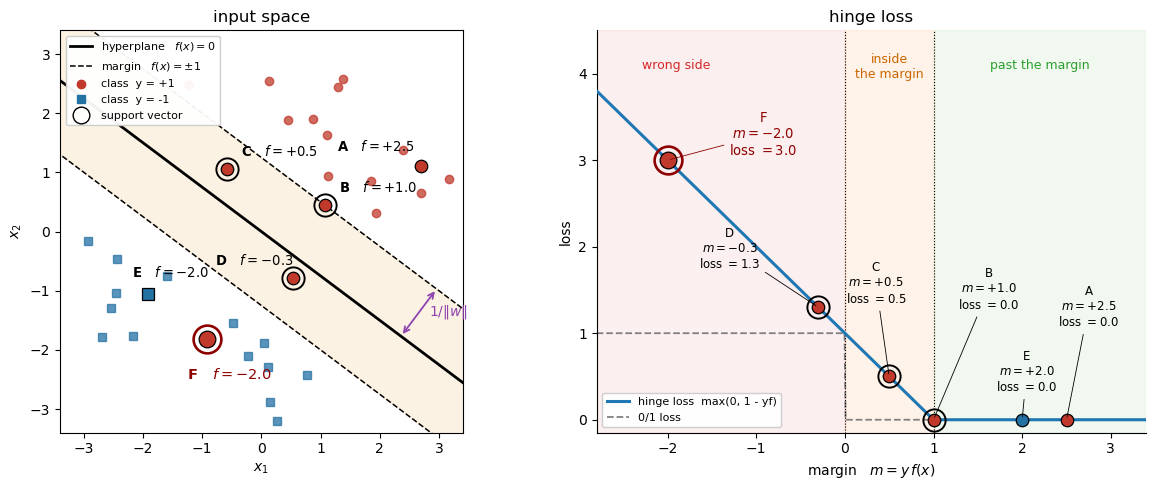

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# DEMO
w, b = np.array([0.6, 0.8]), 0.0
u = np.array([-0.8, 0.6])
place = lambda f, t: f * w + t * u

#        f,    t,   ชื่อ, y,  ที่วางป้ายแผงซ้าย, ที่วางป้ายแผงขวา
named = [(2.5, -1.5, "A", +1, (-1.42, .26), (2.75, 1.05)),
         (1.0, -0.6, "B", +1, (.24, .22), (1.62, 1.25)),
         (0.5, 1.1, "C", +1, (.24, .22), (.35, 1.32)),
         (-0.3, -0.9, "D", +1, (-1.32, .22), (-1.30, 1.72)),
         (-2.0, 0.9, "E", -1, (-.26, .30), (2.05, .30)),
         (-2.0, -0.35, "F", +1, (-.34, -.68), (-.92, 3.02))]

rng = np.random.default_rng(3)
fill = [(rng.uniform(1.25, 3.1), rng.uniform(-2.6, 2.6), +1) for _ in range(14)] \
     + [(rng.uniform(-3.1, -1.25), rng.uniform(-2.6, 2.6), -1) for _ in range(14)]

POS, NEG = "#c0392b", "#2471a3"
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12.4, 5.0),
                               gridspec_kw={"width_ratios": [1.15, 1]})

s = np.array([-5.4, 5.4])
for c, ls, lw, lab in [(0., "-", 2.0, r"hyperplane   $f(x)=0$"),
                       (1., "--", 1.1, r"margin   $f(x)=\pm 1$"), (-1., "--", 1.1, None)]:
    p = np.array([c * w + t * u for t in s])
    axL.plot(p[:, 0], p[:, 1], ls, color="k", lw=lw, label=lab, zorder=4)
band = np.array([w + t * u for t in s] + [-w + t * u for t in s][::-1])
axL.fill(band[:, 0], band[:, 1], color="#f0ad4e", alpha=.15, zorder=0)

for f, t, cls in fill:
    p = place(f, t)
    axL.plot(p[0], p[1], "o" if cls > 0 else "s", ms=6,
             color=POS if cls > 0 else NEG, alpha=.75, zorder=3)

for f, t, lab, cls, lo, ro in named:
    p, m, big = place(f, t), cls * f, lab == "F"
    if m <= 1 + 1e-9:
        axL.plot(p[0], p[1], "o", ms=20 if big else 16, mfc="none",
                 mec="#8e0000" if big else "k", mew=1.9 if big else 1.4, zorder=5)
    axL.plot(p[0], p[1], "o" if cls > 0 else "s", ms=12 if big else 9,
             color=POS if cls > 0 else NEG, mec="k", mew=.9, zorder=6)
    axL.annotate("%s   $f=%+.1f$" % (lab, f), xy=p,
                 xytext=(p[0] + lo[0], p[1] + lo[1]),
                 fontsize=10.5 if big else 9.5, fontweight="bold",
                 color="#8e0000" if big else "k", zorder=7)

mid = -2.95 * u
axL.annotate("", xy=mid + w, xytext=mid, zorder=6,
             arrowprops=dict(arrowstyle="<->", lw=1.3, color="#8e44ad"))
axL.text(*(mid + .5 * w + np.array([.18, -.05])), r"$1/\|w\|$",
         color="#8e44ad", fontsize=10, zorder=7)
axL.plot([], [], "o", color=POS, label="class  y = +1")
axL.plot([], [], "s", color=NEG, label="class  y = -1")
axL.plot([], [], "o", ms=12, mfc="none", mec="k", label="support vector")
axL.set_xlim(-3.4, 3.4); axL.set_ylim(-3.4, 3.4); axL.set_aspect("equal")
axL.set_xlabel("$x_1$"); axL.set_ylabel("$x_2$"); axL.set_title("input space")
axL.legend(loc="upper left", fontsize=8, framealpha=.95)

m = np.linspace(-2.8, 3.4, 500)
axR.axvspan(-2.8, 0., color="#d62728", alpha=.07)
axR.axvspan(0., 1., color="#ff7f0e", alpha=.09)
axR.axvspan(1., 3.4, color="#2ca02c", alpha=.07)
axR.plot(m, np.maximum(0., 1. - m), lw=2.2, color="#1f77b4",
         label="hinge loss  max(0, 1 - yf)", zorder=3)
axR.plot(m, (m < 0).astype(float), lw=1.3, ls="--", color="gray", label="0/1 loss")

for f, t, lab, cls, lo, ro in named:
    mm, L, big = cls * f, max(0., 1. - cls * f), lab == "F"
    if mm <= 1 + 1e-9:
        axR.plot([mm], [L], "o", ms=20 if big else 16, mfc="none",
                 mec="#8e0000" if big else "k", mew=1.9 if big else 1.4, zorder=5)
    axR.plot([mm], [L], "o", ms=12 if big else 9, color=POS if cls > 0 else NEG,
             mec="k", mew=.9, zorder=6)
    axR.annotate("%s\n$m=%+.1f$\nloss $=%.1f$" % (lab, mm, L), xy=(mm, L),
                 xytext=ro, fontsize=9.5 if big else 8.5, ha="center", va="bottom",
                 color="#8e0000" if big else "k",
                 arrowprops=dict(arrowstyle="-", lw=.6,
                                 color="#8e0000" if big else "k"), zorder=7)

axR.axvline(0., color="k", lw=.8, ls=":")
axR.axvline(1., color="k", lw=.8, ls=":")
axR.text(-1.9, 4.05, "wrong side", ha="center", fontsize=9, color="#d62728")
axR.text(0.5, 3.95, "inside\nthe margin", ha="center", fontsize=9, color="#cc6600")
axR.text(2.2, 4.05, "past the margin", ha="center", fontsize=9, color="#2ca02c")
axR.set_xlabel(r"margin   $m = y\,f(x)$"); axR.set_ylabel("loss")
axR.set_xlim(-2.8, 3.4); axR.set_ylim(-.15, 4.5); axR.set_title("hinge loss")
axR.legend(loc="lower left", fontsize=8, framealpha=.95)
axR.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### 3.2 `decide` (12 คะแนน)

คำนวณฟังก์ชันตัดสินใจ และแปลงเป็นป้ายกำกับ

$$f(\mathbf{x}) = \mathbf{w}^\top\mathbf{x} + b
\qquad
\hat{y} = \begin{cases}+1 & f \ge 0\\ -1 & f < 0\end{cases}$$

**ตัวอย่างที่คำนวณให้แล้ว**

```
X = [[0, 1],     w = [1, 1],    b = -0.5
     [1, 0],
     [0, 0],
     [1, 1]]

f = [0*1 + 1*1 - 0.5,     = [ 0.5,        yhat = [ 1,
     1*1 + 0*1 - 0.5,        0.5,                  1,
     0*1 + 0*1 - 0.5,       -0.5,                 -1,
     1*1 + 1*1 - 0.5]        1.5]                  1]
```

**ความหมายของ $f$** ขนาดของ $|f|$ บอกว่าจุดนั้นอยู่ห่างจากเส้นแบ่งแค่ไหน ในหน่วยของระยะขอบ
จุดที่ $|f| < 1$ คือจุดที่อยู่ในแถบขอบ ซึ่งเป็น support vector

**ตรวจรูปร่าง** $X$ ขนาด $(n,p)$ และ $w$ ขนาด $(p,)$ ได้ $f$ ขนาด $(n,)$

**คำใบ้** `np.where(เงื่อนไข, 1, -1)` แปลง boolean เป็นป้ายได้ในบรรทัดเดียว
ระวังว่าเกณฑ์คือ `>= 0` ไม่ใช่ `> 0`

**ถ้าติด** Lab 0 ข้อ 6.1 `linear_model` และข้อ 4.1 เรื่อง boolean

In [ ]:
def decide(X, w, b):
    '''
    ฟังก์ชันตัดสินใจและป้ายที่ทำนาย
    ใส่เข้า : X ขนาด (n, p), w ขนาด (p,), b เป็นตัวเลขตัวเดียว
    ได้ออก  : f ขนาด (n,) และ yhat ขนาด (n,) มีค่า +1 หรือ -1
    '''
    #########################################
    ## เขียนโค้ดของคุณตรงนี้ / INSERT YOUR CODE HERE
    f, yhat = None, None
    #########################################
    return f, yhat

In [ ]:
def test_decide_worked():
    X = np.array([[0., 1.], [1., 0.], [0., 0.], [1., 1.]])
    f, yhat = decide(X, np.array([1., 1.]), -0.5)
    assert f is not None, "ยังไม่ได้เขียนโค้ด ฟังก์ชันคืนค่า None"
    assert f.shape == (4,), "f ต้องมีขนาด (4,) แต่ได้ %s" % (f.shape,)
    assert np.allclose(f, [0.5, 0.5, -0.5, 1.5])
    assert list(yhat) == [1, 1, -1, 1]


def test_decide_boundary_and_shift():
    X = np.array([[0., 1.], [1., 0.], [0., 0.], [1., 1.]])
    _, yhat = decide(X, np.array([1., 1.]), -1.5)
    assert list(yhat) == [-1, -1, -1, 1], "เลื่อน b แล้วเส้นแบ่งต้องเลื่อนตาม"
    _, yhat = decide(np.zeros((1, 2)), np.array([1., 1.]), 0.)
    assert yhat[0] == 1, "ที่ f เท่ากับศูนย์พอดี ให้ตอบ +1 ตามกติกาในโจทย์"


grade("3.2 decide", 12, test_decide_worked, test_decide_boundary_and_shift)

### 3.3 `rbf_kernel` (12 คะแนน)

$$k(\mathbf{x}_1, \mathbf{x}_2) = \exp\!\left(-\gamma\lVert\mathbf{x}_1 - \mathbf{x}_2\rVert^2\right)$$

วัดความคล้ายที่ลดลงตามระยะทาง จุดเดียวกันได้ 1 จุดที่ไกลกันมากได้ 0

**ตัวอย่างที่คำนวณให้แล้ว** $\mathbf{x}_1 = (0,1)$ และ $\mathbf{x}_2 = (1,0)$ กับ $\gamma = 0.5$

```
ผลต่าง        = (-1, 1)
ระยะยกกำลังสอง = 1 + 1 = 2        <- ไม่ต้องถอดราก สูตรใช้กำลังสอง
-gamma * 2    = -1
exp(-1)       = 0.3679
```

**$\gamma$ คือปุ่มความยืดหยุ่นของ SVM แบบ RBF** $\gamma$ ใหญ่แปลว่าความคล้ายลดลงเร็ว
แต่ละจุดเห็นแค่เพื่อนบ้านใกล้ ๆ เส้นแบ่งจึงหยักตามข้อมูลได้มาก ส่วน $\gamma$ เล็กทำให้เส้นเรียบ
เป็นปุ่มเดียวกับ $K$ ใน kNN และความลึกในต้นไม้ เพียงแต่คนละชื่อ

**$k$ ถูกเอาไปใช้ตรงไหน** คำตอบของ SVM มีสมบัติว่า $\mathbf{w} = \sum_i \alpha_i y_i \mathbf{x}_i$ เสมอ
แทนลงในฟังก์ชันตัดสินใจแล้ว $\mathbf{w}$ จะหายไป เหลือข้อมูลในรูปผลคูณภายในอย่างเดียว

$$f(\mathbf{x}) = \mathbf{w}^\top\mathbf{x} + b
= \sum_i \alpha_i y_i\, \mathbf{x}_i^\top\mathbf{x} + b
\qquad\xrightarrow{\ \text{เปลี่ยนเป็น } k\ }\qquad
f(\mathbf{x}) = \sum_i \alpha_i y_i\, k(\mathbf{x}_i, \mathbf{x}) + b$$

ลูกศรนั้นคือ **kernel trick** ทั้งหมด ไม่มีขั้นตอนอื่นอีก และ $\alpha_i$ ไม่เป็นศูนย์เฉพาะ support vector
ผลรวมจึงสั้นกว่าที่เห็น เมทริกซ์ที่ฟังก์ชันในข้อนี้คืนออกมา ก็คือค่า $k$ ทุกคู่ในผลรวมนั้นพอดี

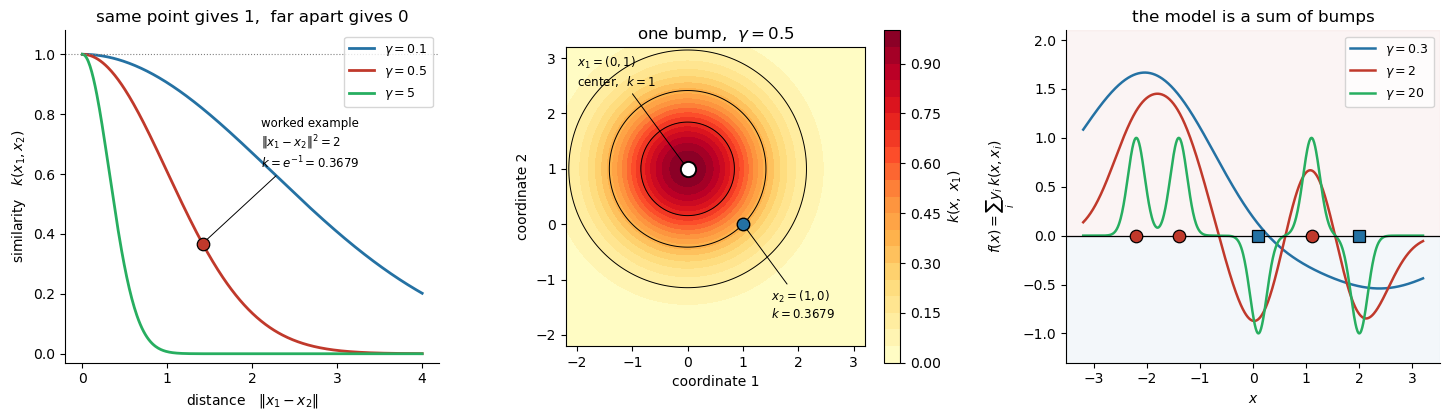

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# DEMO
fig, ax = plt.subplots(1, 3, figsize=(14.6, 4.3))

d = np.linspace(0, 4, 400)
for g, c in [(0.1, "#2471a3"), (0.5, "#c0392b"), (5.0, "#27ae60")]:
    ax[0].plot(d, np.exp(-g * d ** 2), lw=2., color=c, label=r"$\gamma = %g$" % g)
d0 = np.sqrt(2.)
ax[0].plot([d0], [np.exp(-1.)], "o", ms=9, color="#c0392b", mec="k", mew=.9, zorder=5)
ax[0].annotate("worked example\n$\\|x_1-x_2\\|^2 = 2$\n$k = e^{-1} = 0.3679$",
               xy=(d0, np.exp(-1.)), xytext=(2.1, .62), fontsize=8.5,
               arrowprops=dict(arrowstyle="-", lw=.7, color="k"))
ax[0].axhline(1., ls=":", lw=.8, color="gray")
ax[0].set_xlabel(r"distance   $\|x_1 - x_2\|$")
ax[0].set_ylabel(r"similarity   $k(x_1, x_2)$")
ax[0].set_title("same point gives 1,  far apart gives 0")
ax[0].set_ylim(-.03, 1.08)
ax[0].legend(fontsize=9)
ax[0].spines[["top", "right"]].set_visible(False)

g = 0.5
gx, gy = np.meshgrid(np.linspace(-2.2, 3.2, 300), np.linspace(-2.2, 3.2, 300))
x1, x2 = np.array([0., 1.]), np.array([1., 0.])
K = np.exp(-g * ((gx - x1[0]) ** 2 + (gy - x1[1]) ** 2))
im = ax[1].contourf(gx, gy, K, levels=np.linspace(0, 1, 21), cmap="YlOrRd")
plt.colorbar(im, ax=ax[1], label=r"$k(x,\; x_1)$")
ax[1].contour(gx, gy, K, levels=[.1, .3679, .7], colors="k", linewidths=.7)
ax[1].plot(*x1, "o", ms=11, color="w", mec="k", mew=1.4, zorder=5)
ax[1].plot(*x2, "o", ms=9, color="#2471a3", mec="k", mew=1., zorder=5)
ax[1].annotate(r"$x_1 = (0,1)$" + "\ncenter,  $k = 1$", xy=x1, xytext=(-2.0, 2.5),
               fontsize=8.5, arrowprops=dict(arrowstyle="-", lw=.7, color="k"))
ax[1].annotate(r"$x_2 = (1,0)$" + "\n$k = 0.3679$", xy=x2, xytext=(1.5, -1.7),
               fontsize=8.5, arrowprops=dict(arrowstyle="-", lw=.7, color="k"))
ax[1].set_aspect("equal")
ax[1].set_xlabel("coordinate 1")
ax[1].set_ylabel("coordinate 2")
ax[1].set_title(r"one bump,  $\gamma = 0.5$")

xs = np.array([-2.2, -1.4, 0.1, 1.1, 2.0])
ys = np.array([1., 1., -1., 1., -1.])
t = np.linspace(-3.2, 3.2, 700)
for g, c in [(0.3, "#2471a3"), (2.0, "#c0392b"), (20., "#27ae60")]:
    f = sum(y * np.exp(-g * (t - x) ** 2) for x, y in zip(xs, ys))
    ax[2].plot(t, f, color=c, lw=1.8, label=r"$\gamma = %g$" % g)
ax[2].axhline(0., color="k", lw=.9)
for x, y in zip(xs, ys):
    ax[2].plot([x], [0.], "o" if y > 0 else "s", ms=9,
               color="#c0392b" if y > 0 else "#2471a3", mec="k", mew=.9, zorder=5)
ax[2].axhspan(0, 2.1, color="#c0392b", alpha=.05)
ax[2].axhspan(-1.3, 0, color="#2471a3", alpha=.05)
ax[2].set_ylim(-1.3, 2.1)
ax[2].set_xlabel("$x$")
ax[2].set_ylabel(r"$f(x) = \sum_i y_i\, k(x, x_i)$")
ax[2].set_title("the model is a sum of bumps")
ax[2].legend(fontsize=9, loc="upper right")
ax[2].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**ตรวจรูปร่าง** `X1` ขนาด `(n1, p)` และ `X2` ขนาด `(n2, p)` ต้องได้ `(n1, n2)`
ไม่จำเป็นต้องจัตุรัส

**คำใบ้** โครงเหมือนข้อ 1.1 ทุกประการ ต่างกันแค่ตอนจบ ข้อ 1.1 ถอดราก ส่วนข้อนี้
เอาระยะยกกำลังสองไปใส่ใน `np.exp` เลย

**ถ้าติด** Lab 0 ข้อ 2.5 เรื่อง `np.exp`

In [ ]:
def rbf_kernel(X1, X2, gamma=0.5):
    '''
    เมทริกซ์ kernel แบบเกาส์เซียน
    ใส่เข้า : X1 ขนาด (n1, p), X2 ขนาด (n2, p), gamma เป็นตัวเลขบวก
    ได้ออก  : K ขนาด (n1, n2)
    '''
    #########################################
    ## เขียนโค้ดของคุณตรงนี้ / INSERT YOUR CODE HERE
    K = None
    #########################################
    return K

In [ ]:
def test_rbf_kernel_worked():
    X = np.array([[0., 1.], [1., 0.]])
    K = rbf_kernel(X, X, gamma=0.5)
    assert K is not None, "ยังไม่ได้เขียนโค้ด ฟังก์ชันคืนค่า None"
    assert K.shape == (2, 2)
    assert np.allclose(np.diag(K), 1.), "จุดเดียวกันต้องได้ความคล้ายเท่ากับ 1"
    assert np.allclose(K[0, 1], 0.3679, atol=1e-4), \
        "ตัวอย่างในโจทย์คำนวณไว้ได้ 0.3679 แต่ได้ %s  ลืมว่าสูตรใช้ระยะกำลังสองหรือเปล่า" % K[0, 1]


def test_rbf_kernel_shape_and_gamma():
    rng = np.random.default_rng(0)
    A, B = rng.normal(0., 1., (5, 3)), rng.normal(0., 1., (7, 3))
    assert rbf_kernel(A, B).shape == (5, 7), "ต้องได้ (n1, n2) ไม่จำเป็นต้องจัตุรัส"
    far = np.array([[0., 0.], [100., 100.]])
    assert np.allclose(rbf_kernel(far, far, gamma=0.5)[0, 1], 0., atol=1e-10), \
        "จุดที่ไกลกันมากต้องได้ความคล้ายเกือบศูนย์"
    X = np.array([[0., 0.], [1., 0.]])
    assert rbf_kernel(X, X, gamma=5.)[0, 1] < rbf_kernel(X, X, gamma=0.1)[0, 1], \
        "gamma ใหญ่ขึ้น ความคล้ายต้องลดลงเร็วขึ้น"


def test_rbf_kernel_matches_sklearn():
    '''เทียบกับของจริง ซึ่งไม่รู้สูตรที่คุณเขียนเลย'''
    from sklearn.metrics.pairwise import rbf_kernel as sk_rbf
    rng = np.random.default_rng(1)
    A, B = rng.normal(0., 1., (6, 2)), rng.normal(0., 1., (4, 2))
    assert np.allclose(rbf_kernel(A, B, gamma=0.7), sk_rbf(A, B, gamma=0.7), atol=1e-10)


grade("3.3 rbf_kernel", 12, test_rbf_kernel_worked,
      test_rbf_kernel_shape_and_gamma, test_rbf_kernel_matches_sklearn)

### ฝึกด้วย sklearn แล้วเปิดดูข้างใน

ตอนนี้เรามีชิ้นส่วนครบแล้ว ให้ sklearn แก้ปัญหาการหาค่าเหมาะที่สุด แล้วเราเอาผลมาตรวจ
ด้วยฟังก์ชันที่เขียนเอง สังเกตสามอย่าง คือจำนวน support vector, ค่า hinge loss,
และความถูกต้องของ kernel สองแบบ

In [ ]:
# DEMO
try:
    from sklearn.svm import SVC

    y_tr_pm = np.where(y_tr == 1, 1, -1)       # SVM ใช้ป้าย +1 และ -1
    y_te_pm = np.where(y_te == 1, 1, -1)

    lin = SVC(kernel="linear", C=1.0).fit(X_tr, y_tr_pm)
    rbf = SVC(kernel="rbf", C=1.0, gamma=0.5).fit(X_tr, y_tr_pm)

    f_lin, yhat_lin = decide(X_tr, lin.coef_.ravel(), float(lin.intercept_[0]))
    print("linear kernel")
    print("  support vectors   ", lin.n_support_.sum(), "จาก", len(y_tr), "จุด")
    print("  hinge loss ชุดฝึก  ", round(hinge_loss(y_tr_pm, f_lin), 4))
    print("  ความถูกต้องชุดทดสอบ", (lin.predict(X_te) == y_te_pm).mean())

    print("rbf kernel")
    print("  support vectors   ", rbf.n_support_.sum(), "จาก", len(y_tr), "จุด")
    print("  ความถูกต้องชุดทดสอบ", (rbf.predict(X_te) == y_te_pm).mean())
    print()
    print("เส้นตรงแบ่งข้อมูลชุดนี้ไม่ได้ จึงมี support vector เยอะมาก")
    print("เพราะเกือบทุกจุดล้ำเข้ามาในขอบหรืออยู่ผิดฝั่ง")
except Exception as _e:
    print("เซลล์นี้ต้องทำข้อข้างบนให้เสร็จก่อน")
    print("  %s: %s" % (type(_e).__name__, _e))


In [ ]:
# เส้นแบ่งเขตของ SVM สองแบบ จุดวงกลมใหญ่คือ support vector
try:
    xx, yy = np.meshgrid(np.linspace(X_all[:, 0].min() - .5, X_all[:, 0].max() + .5, 200),
                         np.linspace(X_all[:, 1].min() - .5, X_all[:, 1].max() + .5, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, model, name in [(axes[0], lin, "linear"), (axes[1], rbf, "rbf, gamma = 0.5")]:
        zz = model.decision_function(grid).reshape(xx.shape)
        ax.contourf(xx, yy, zz > 0, alpha=.2, cmap="coolwarm")
        ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors="k",
                   linestyles=["--", "-", "--"], linewidths=[.8, 1.5, .8])
        ax.scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap="coolwarm", s=14,
                   edgecolors="k", linewidths=.3)
        sv = model.support_vectors_
        ax.scatter(sv[:, 0], sv[:, 1], s=70, facecolors="none", edgecolors="k", linewidths=.7)
        ax.set_title("%s   acc = %.3f" % (name, (model.predict(X_te) == y_te_pm).mean()))
    plt.tight_layout()
    plt.show()
except Exception as _e:
    print("เซลล์นี้ต้องทำข้อข้างบนให้เสร็จก่อน")
    print("  %s: %s" % (type(_e).__name__, _e))


---
# 4. เปรียบเทียบทั้งสามวิธี (ไม่คิดคะแนน แต่ต้องส่ง)

ข้อมูลชุดเดียว สามวิธี วาดเส้นแบ่งเขตมาวางข้างกัน

ก่อนรัน **ลองทายก่อนว่าเส้นแบ่งของแต่ละวิธีจะหน้าตาอย่างไร** แล้วค่อยดูว่าตรงกับที่ทายไหม

In [ ]:

try:
    xx, yy = np.meshgrid(np.linspace(X_all[:, 0].min() - .5, X_all[:, 0].max() + .5, 180),
                         np.linspace(X_all[:, 1].min() - .5, X_all[:, 1].max() + .5, 180))
    grid = np.c_[xx.ravel(), yy.ravel()]

    tree = build_tree(X_tr, y_tr, max_depth=6, min_samples=5)
    models = [
        ("kNN, K = 5", lambda G: knn_predict(X_tr, y_tr, G, K=5)),
        ("decision tree, depth 6", lambda G: tree_predict(tree, G)),
        ("SVM, rbf kernel", lambda G: np.where(rbf.predict(G) == 1, 1, 0)),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4))
    for ax, (name, f) in zip(axes, models):
        zz = f(grid).reshape(xx.shape)
        acc = (np.asarray(f(X_te)) == y_te).mean()
        ax.contourf(xx, yy, zz, alpha=.25, cmap="coolwarm", levels=1)
        ax.scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap="coolwarm", s=12,
                   edgecolors="k", linewidths=.25)
        ax.set_title("%s\ntest accuracy = %.3f" % (name, acc))
    plt.tight_layout()
    plt.show()
except Exception as _e:
    print("เซลล์นี้ต้องทำข้อข้างบนให้เสร็จก่อน")
    print("  %s: %s" % (type(_e).__name__, _e))


In [ ]:
# ตารางสรุป
print("%-26s %-10s %-10s" % ("", "train", "test"))
rows = [
    ("kNN, K = 5", knn_predict(X_tr, y_tr, X_tr, K=5), knn_predict(X_tr, y_tr, X_te, K=5)),
    ("kNN, K = 1", knn_predict(X_tr, y_tr, X_tr, K=1), knn_predict(X_tr, y_tr, X_te, K=1)),
    ("tree, depth 6", tree_predict(tree, X_tr), tree_predict(tree, X_te)),
    ("tree, depth 1", tree_predict(build_tree(X_tr, y_tr, max_depth=1), X_tr),
                      tree_predict(build_tree(X_tr, y_tr, max_depth=1), X_te)),
    ("SVM linear", np.where(lin.predict(X_tr) == 1, 1, 0), np.where(lin.predict(X_te) == 1, 1, 0)),
    ("SVM rbf", np.where(rbf.predict(X_tr) == 1, 1, 0), np.where(rbf.predict(X_te) == 1, 1, 0)),
]
for name, a, b in rows:
    print("%-26s %-10.3f %-10.3f" % (name, (a == y_tr).mean(), (b == y_te).mean()))

### คำถามสำหรับส่ง

ตอบในเซลล์ข้างล่าง ข้อละสองสามบรรทัด ตอบจากตัวเลขและภาพที่เห็นจริง

In [ ]:
# เขียนคำตอบเป็นคอมเมนต์ ตอบเป็นภาษาไทยได้
#
# 1. ดูภาพเส้นแบ่งเขตทั้งสามภาพ บรรยายรูปร่างของแต่ละเส้นสั้น ๆ
#    เส้นของต้นไม้ต่างจากอีกสองอันอย่างชัดเจน ต่างอย่างไร และทำไมถึงเป็นแบบนั้น
#
#
# 2. ที่ K = 1 ความถูกต้องบนชุดฝึกเป็นเท่าไหร่ และเกิดจากอะไร
#    เพื่อนบ้านที่ใกล้ที่สุดของจุดในชุดฝึกคือจุดอะไร
#    ตัวเลขนี้บอกอะไรเกี่ยวกับความสามารถของโมเดลบ้าง และไม่บอกอะไร
#    ถ้าข้อมูลมีจุดที่พิกัดซ้ำกันแต่ป้ายต่างกัน ตัวเลขนี้จะเปลี่ยนไปไหม
# 
#
# 3. จากตาราง วิธีไหนได้ความถูกต้องบนชุดทดสอบสูงสุด และห่างจากอันดับสองเท่าไหร่
#    ถ้าสลับ seed ของข้อมูลแล้วรันใหม่ คุณคิดว่าอันดับจะเปลี่ยนไหม เพราะอะไร
#
#
# 4. ทั้งสามวิธีมีปุ่มปรับ "ความซับซ้อนของโมเดล" คนละตัว คือ K, ความลึก, และ gamma
#    ก. เติมตารางนี้ให้ครบ ช่องขวาตอบด้วยคำว่า มากขึ้น หรือ น้อยลง เท่านั้น
#
#        วิธี            หมุนปุ่มไปทาง      แล้วหนึ่งคำทำนายอาศัยจุดในชุดฝึก
#        kNN            K ..........      ..........
#        decision tree  ความลึก ......    ..........
#        SVM rbf        gamma ........    ..........
#
#       โดยให้หมุนไปในทางที่ทำให้โมเดลซับซ้อนขึ้นจนเริ่ม overfit

---
## คะแนนของคุณ

In [ ]:
report()

---
## สิ่งที่ได้จากแลปนี้

* ทุกวิธีมีปุ่มความยืดหยุ่นอันเดียว $K$ ในเพื่อนบ้าน ความลึกในต้นไม้ $\gamma$ ใน RBF
และหลังจากนี้จะเป็นจำนวนชั้นกับจำนวนหน่วยในโครงข่าย ชื่อเปลี่ยน แต่ปัญหาเดิมทุกครั้ง
คือยืดหยุ่นน้อยไปก็ลำเอียง ยืดหยุ่นมากไปก็แปรปรวน

* ความถูกต้องบนชุดฝึกแทบไม่บอกอะไร kNN ที่ $K=1$ ได้ 100 เปอร์เซ็นต์บนชุดฝึกเสมอ
โดยไม่ต้องเรียนรู้อะไรเลย ตัวเลขที่มีความหมายคือตัวเลขบนข้อมูลที่โมเดลไม่เคยเห็น
ข้อนี้จะกลับมาเป็นประเด็นใหญ่ตอนที่เราฝึกโครงข่ายที่มีพารามิเตอร์มากกว่าจำนวนข้อมูล

แลปหน้าเริ่มสร้าง regression ซึ่งเป็นวิธีเดียวในวิชานี้
ที่เรารู้คำตอบที่ถูกต้องล่วงหน้า และใช้มันตรวจงานของตัวเองได้